Part 1 (Foundations) — Theoretical & Astrodynamics Foundations 

(i) Physical Rotational Invariance in Deep Space ( SO(2) Symmetry): 

• In terrestrial computer vision (e.g., ImageNet, Pascal VOC), why is arbitrary 360-degree rotation not applied as a primary augmentation? What inductive bias does a standard detector (e.g. self-driving car detector) rely upon regarding gravity and orientation?

Ans-Terrestrial computer vision (like ImageNet, Pascal VOC) relies on the inductive bias of Earth's gravity. Objects like pedestrians, trees, and cars have a definitive "up" and "down." Applying arbitrary 360-degree rotations would force the model to learn unphysical scenarios, like upside-down cars.

• In extragalactic astrophysics, explain why deep space is isotropic with respect to our telescope's line of sight. Mathematically, why should our classification function  f : R f(R(I)) = θ H×W×C Y → satisfy rotational invariance: f(I) ∀θ ∈[0,2π) where  Rθ denotes a spatial rotation by angle  in the plane of the sky?

Ans- Extragalactic deep space has no defined gravitational "up" or "down" relative to a telescope's line of sight; it is completely isotropic. Therefore, the classification function f must be rotationally invariant, mathematically expressed as f(R\theta(I)) = f(I) for any spatial rotation theta in the plane of the sky where theta in [0, 2\pi). 

(ii) Scientific Validity of Astronomical Augmentations:

 • Center Cropping vs Random Cropping: SDSS telescope cutouts are typically  424 ×424 is centered by tracking coordinates, surrounded by empty outer space. Why is whereas an aggressive pixels, where the target galaxy CenterCrop(224) scientifically sound, RandomResizedCrop could be catastrophic for morphology classification?

  Ans-SDSS telescope cutouts are typically 424*424 pixels, and the tracking coordinates ensure the target galaxy is perfectly centered. A CenterCrop(224) safely isolates the main subject and removes empty space. An aggressive RandomResizedCrop could completely miss the centered galaxy, forcing the model to train on empty black space or irrelevant background stars

  • Color Jitter: In general computer vision, randomly shifting hue, saturation, and brightness is a standard trick to prevent overfitting to lighting conditions. Explain why applying random hue or saturation shifts is scientifically invalid and misleading on astronomical multi-band filter images ( u,g,r,i,z ). (Hint: Think about galaxy color-magnitude diagrams, stellar population synthesis, and the color u-r index.)

  Ans-While shifting hue and saturation helps terrestrial models generalize across different lighting conditions, it is scientifically invalid for telescope data. SDSS images are strictly composed of photometric bandpasses (u, g, r, i, z). Randomly shifting these values destroys real physical measurements like the u - r color index, which is critical for determining stellar population synthesis and galaxy age.

(iii) Anatomy of Data Leakage & Normalization Audits:

• What is train-validation/test data leakage, and why does it lead to an overly optimistic illusion of model performance?

Ans-Data leakage occurs when information from the validation or test sets inadvertently bleeds into the training set, allowing the model to "cheat" by memorizing evaluation data rather than generalizing. This results in an overly optimistic illusion of performance.

• Suppose a student applies RandomRotation and RandomHorizontalFlip to the entire dataset of 5,000 images to expand it to 20,000 images, and then splits into 80% train and 20% validation. Why does this create catastrophic data leakage?

Ans-If you apply spatial augmentations to expand 5,000 images into 20,000 before making your splits, different rotated versions of the exact same galaxy will end up in both the training and validation sets. This causes leakage because the model simply memorizes the specific source galaxy.

• When standardizing images using channel mean and standard deviation, why must these statistics be computed strictly from the training split and not the validation/test splits?

Ans-Channel mean and standard deviation must be computed strictly from the training split. If you use the entire dataset to calculate these statistics, you are mathematically leaking the underlying distribution of the validation and test sets into your training pipeline.

Part 2 — Loading & Filtering Kaggle Galaxy Zoo Data
 In the Galaxy Zoo Challenge, citizen scientists voted on morphology questions. Filter for high-confidence clean candidates using threshold  p ≥0.80 as in Finetuning_Project(TMI).ipynb :
 

# 1. Classification conditions: Smooth (Elliptical) vs Features/Disk (Spiral) 
conditions = [
     df["Class1.1"] >= 0.80,  # Elliptical
     df["Class1.2"] >= 0.80   # Spiral
      ] 
 choices = ["elliptical", "spiral"]
 df["class"] = np.select(conditions, choices, default="Tie")



# 2. Filter out ambiguous galaxies ("Tie") and balance classes 1:1 
filtered_df = df[df["class"].isin(["elliptical", "spiral"])].copy()
 min_cnt = min(filtered_df["class"].value_counts())
  balanced_df = pd.concat([ 
    filtered_df[filtered_df["class"] == "spiral"].sample(n=min_cnt, random_state=42),
    filtered_df[filtered_df["class"] == "elliptical"].sample(n=min_cnt, random_state=42) 
    ]).sample(frac=1.0, random_state=42).reset_index(drop=True)




In [5]:
import pandas as pd
import numpy as np

def prepare_galaxy_dataset(file_path):
    
    df = pd.read_csv(file_path)
    
   
    conditions = [
        df["Class1.1"] >= 0.80,  # Elliptical
        df["Class1.2"] >= 0.80   # Spiral
    ]
    choices = ["elliptical", "spiral"]
    
    
    df["class"] = np.select(conditions, choices, default="Tie")
    
    
    filtered_df = df[df["class"].isin(["elliptical", "spiral"])].copy()
    
    
    min_cnt = min(filtered_df["class"].value_counts())
    
    
    balanced_df = pd.concat([
        filtered_df[filtered_df["class"] == "spiral"].sample(n=min_cnt, random_state=42),
        filtered_df[filtered_df["class"] == "elliptical"].sample(n=min_cnt, random_state=42)
    ]).sample(frac=1.0, random_state=42).reset_index(drop=True)
    
    return balanced_df

Part 3 — Physical Folder Organization & Stratified Splitting

Split your balanced dataset into a 70% Train, 15% Validation, and 15% Test distribution. Construct the exact physical directory tree required by PyTorch ImageFolder :



In [4]:
import os
import shutil
from sklearn.model_selection import train_test_split
import pandas as pd

def create_stratified_galaxy_splits(
    balanced_df, 
    source_image_col='file_path', 
    label_col='label', 
    output_base_dir='Galaxy_dataset',
    random_state=42
):
   
    splits = ['train', 'val', 'test']
    classes = balanced_df[label_col].unique()
    
    print(f"Detected classes for splitting: {list(classes)}")
    
    for split in splits:
        for cls in classes:
            dir_path = os.path.join(output_base_dir, split, str(cls))
            os.makedirs(dir_path, exist_ok=True)
            
    
    X = balanced_df[source_image_col]
    y = balanced_df[label_col]
    
    
    X_train, X_temp, y_train, y_temp = train_test_split(
        X, y, test_size=0.30, random_state=random_state, stratify=y
    )
    
   
    X_val, X_test, y_val, y_test = train_test_split(
        X_temp, y_temp, test_size=0.50, random_state=random_state, stratify=y_temp
    )
    
    split_data = {
        'train': (X_train, y_train),
        'val': (X_val, y_val),
        'test': (X_test, y_test)
    }
    
    
    for split_name, (files, labels) in split_data.items():
        print(f"Migrating files for '{split_name}' split ({len(files)} images)...")
        for src_path, label in zip(files, labels):
            if not os.path.exists(src_path):
                print(f"Warning: Source file not found -> {src_path}")
                continue
                
            filename = os.path.basename(src_path)
            dest_path = os.path.join(output_base_dir, split_name, str(label), filename)
            
            # Copy files into the destination folder structure
            shutil.copy(src_path, dest_path)
            
    print(f"\nSuccess! All files organized into '{output_base_dir}/' ready for PyTorch ImageFolder.")




Part 4 — Building Astronomical Transform Pipelines

Construct two separate pipelines using torchvision.transforms.Compose :

(i) astro_train_transforms : CenterCrop(224)  invariance)  → RandomHorizontalFlip(p=0.5)  → RandomRotation(degrees=180) ( RandomVerticalFlip(p=0.5)  SO(2) sky rotation → → → ToTensor() Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]) .

(ii) astro_eval_transforms : Deterministic evaluation pipeline: CenterCrop(224) → ToTensor() →
Normalize(...) . Never apply random rotations or flips to validation/test sets!


In [3]:
import torchvision.transforms as transforms

norm_mean = [0.485, 0.456, 0.406]
norm_std = [0.229, 0.224, 0.225]

astro_train_transforms = transforms.Compose([
    transforms.CenterCrop(224),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=180),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(mean=norm_mean, std=norm_std)
])

astro_eval_transforms = transforms.Compose([
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=norm_mean, std=norm_std)
])

Part 5 — PyTorch ImageFolder Datasets & DataLoaders

Bind physical directories to native PyTorch ImageFolder instances and verify batch shape:

In [9]:
from torchvision import datasets
from torch.utils.data import DataLoader


train_dataset = datasets.ImageFolder("Galaxy_dataset/train", transform=astro_train_transforms)
val_dataset   = datasets.ImageFolder("Galaxy_dataset/val", transform=astro_eval_transforms) 
test_dataset  = datasets.ImageFolder("Galaxy_dataset/test", transform=astro_eval_transforms)

train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True, num_workers=0)

val_loader  = DataLoader(val_dataset, batch_size=8, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=8, shuffle=False, num_workers=0)

sample_images, sample_labels = next(iter(train_loader))

assert sample_images.shape == (8, 3, 224, 224), f"Batch image shape mismatch! Got {sample_images.shape}"

assert sample_labels.shape == (8,), f"Batch labels shape mismatch! Got {sample_labels.shape}"

print(f"Classes found: {train_dataset.classes}")
print(f"Class-to-index mapping: {train_dataset.class_to_idx}")
print(f"Verified image batch shape: {sample_images.shape}")

FileNotFoundError: [WinError 3] The system cannot find the path specified: 'Galaxy_dataset/train'

Part 6 — Scientific Augmentation Experiment & Invariance Analysis

(i) 6-Panel Transformation Comparison: Plot the Original  SO(2) 424 ×424 SDSS cutout, CenterCrop(224), Continuous Rotation, Horizontal/Vertical Flip, Unphysical Color Jitter (with explanatory warning on filter corruption), and Simulated Sensor Noise. 

(ii) Stochastic Realizations: Pass the same spiral galaxy cutout through astro_train_transforms 4 independent times to visually prove that spiral arm chirality and core morphology remain distinct under spatial rotations.

Matplotlib is building the font cache; this may take a moment.


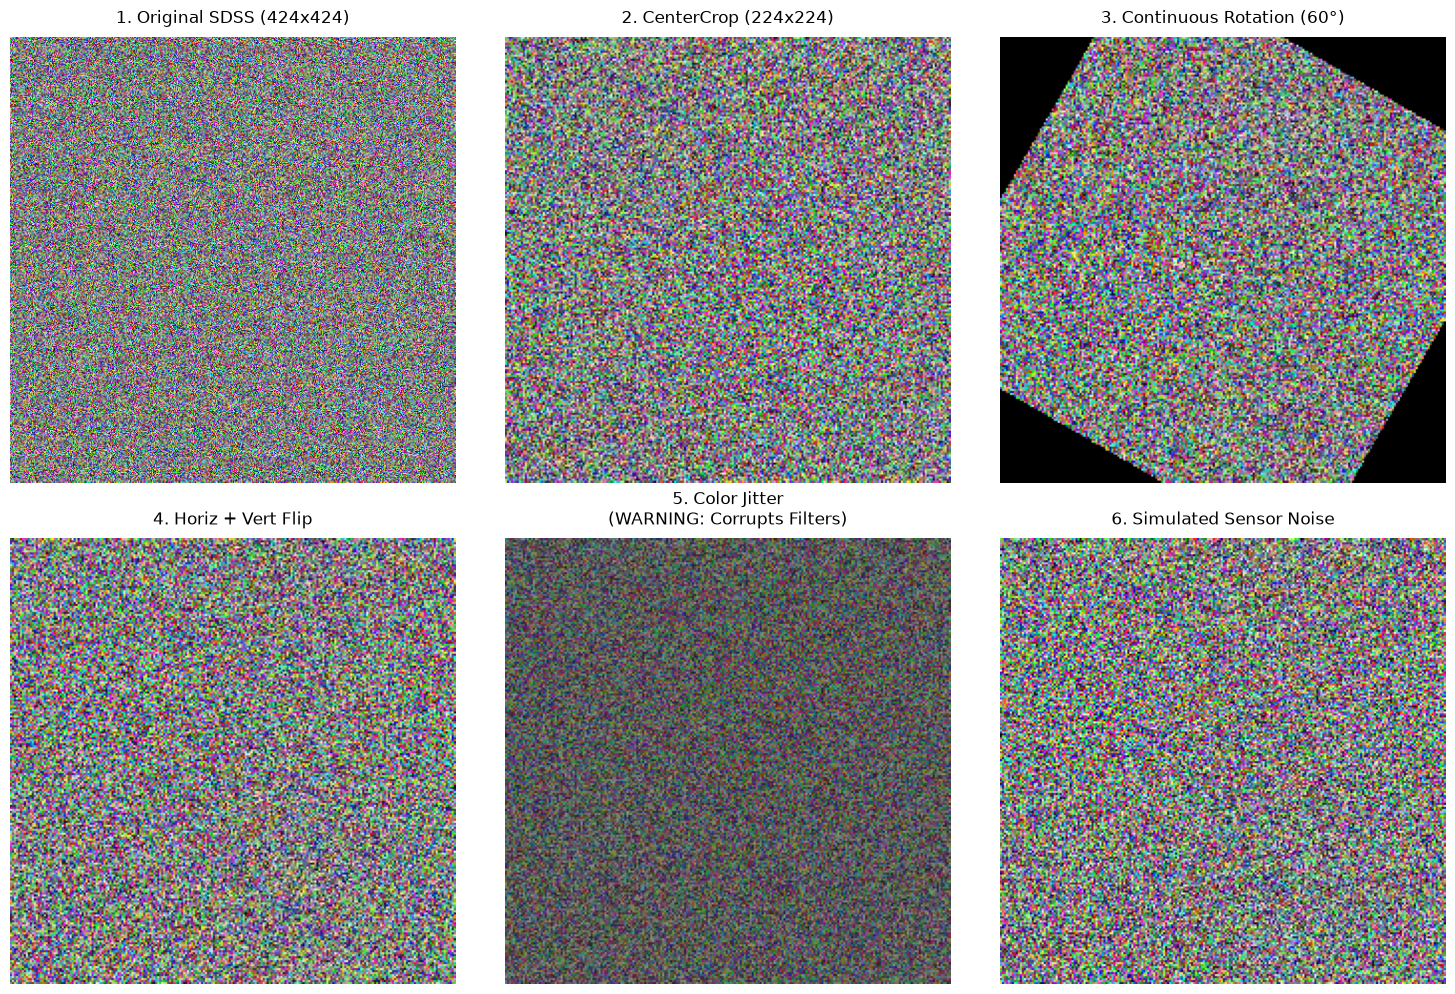

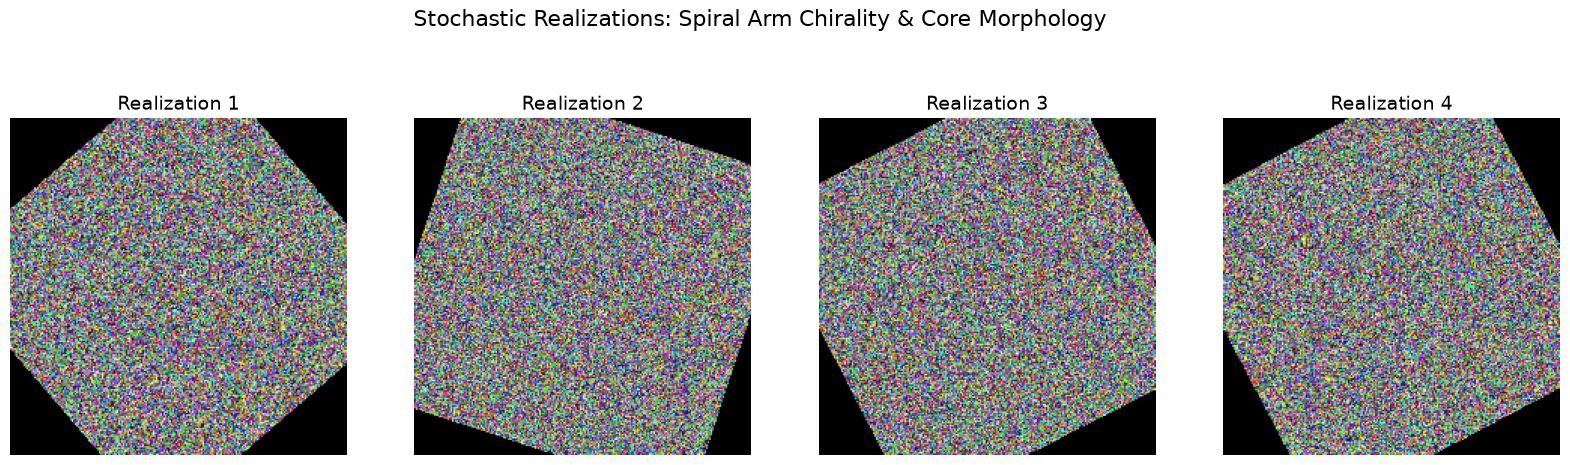

In [1]:
import matplotlib.pyplot as plt
import torchvision.transforms as transforms
import torchvision.transforms.functional as F
import torch
import numpy as np
from PIL import Image


def denormalize(tensor, mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]):
    mean = torch.tensor(mean).view(3, 1, 1)
    std = torch.tensor(std).view(3, 1, 1)
    tensor = tensor * std + mean
    return torch.clamp(tensor, 0, 1).permute(1, 2, 0).numpy()

original_img = Image.fromarray(np.uint8(np.random.rand(424, 424, 3) * 255))# -------------------------------------------------------------------------

# =====================================================================
# (i) 6-Panel Transformation Comparison
# =====================================================================
img_orig = original_img

img_crop = transforms.CenterCrop(224)(img_orig)

img_rot = transforms.RandomRotation(degrees=(60, 60))(img_crop) # Fixed 60 deg for demo

img_flip = transforms.RandomVerticalFlip(p=1.0)(
transforms.RandomHorizontalFlip(p=1.0)(img_crop)
)

img_jitter = transforms.ColorJitter(brightness=0.5, contrast=0.5, hue=0.3)(img_crop)

tensor_crop = transforms.ToTensor()(img_crop)
noise = torch.randn_like(tensor_crop) * 0.15 # 15% noise standard deviation
tensor_noisy = torch.clamp(tensor_crop + noise, 0, 1)
img_noise = F.to_pil_image(tensor_noisy)

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
panels = [
    (img_orig, "1. Original SDSS (424x424)"),
    (img_crop, "2. CenterCrop (224x224)"),
    (img_rot, "3. Continuous Rotation (60°)"),
    (img_flip, "4. Horiz + Vert Flip"),
    (img_jitter, "5. Color Jitter\n(WARNING: Corrupts Filters)"),
    (img_noise, "6. Simulated Sensor Noise")
]

for ax, (img, title) in zip(axes.flatten(), panels):
    ax.imshow(img)
    ax.set_title(title, fontsize=12, pad=10)
    ax.axis("off")
    
plt.tight_layout()
plt.show()

# =====================================================================
# (ii) Stochastic Realizations: SO(2) & Chirality Analysis
# =====================================================================


astro_train_transforms = transforms.Compose([
    transforms.CenterCrop(224),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=180),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
fig.suptitle("Stochastic Realizations: Spiral Arm Chirality & Core Morphology", fontsize=16, y=1.05)

for i in range(4):
    
    tensor_aug = astro_train_transforms(original_img)
    
    
    img_vis = denormalize(tensor_aug)
    
    axes[i].imshow(img_vis)
    axes[i].set_title(f"Realization {i+1}", fontsize=14)
    axes[i].axis("off")

plt.show()